In [1]:
# import modules
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import seaborn as sns
from pylab import rcParams
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras import optimizers
from datetime import datetime
from kerastuner.tuners import RandomSearch
import tensorflow_addons as tfa
from keras.utils import to_categorical 
from keras.regularizers import l2




r_seed = 42

from pathlib import Path
WORKDIR = str(Path.cwd().parent) + '/'  # raiz do repositório
np.random.seed(r_seed)
tf.random.set_seed(r_seed)
data_hora= datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
LOG_DIR = WORKDIR + "/Data/processed/2024-03-15_21-38-39 - Copia"

In [2]:
date = datetime.now()
date = date.strftime("%d/%m/%Y_%H:%M")
arq = datetime.now()
arq = arq.strftime("%d_%m_%Y_%H_%M")

In [3]:
## get dataset
pd.set_option("display.precision", 9)

# select only sensor data from smart watches
data = pd.read_csv(WORKDIR + 'Data/processed/activity_recognition_data_watch_concat_by_comparacao_grupos.csv',dtype={"value": "float64"})

In [4]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [5]:
data.isnull().sum()

pessoa_x              0
atividade             0
tempo_acelerômetro    0
acelerômetro_x        0
acelerômetro_Y        0
acelerômetro_Z        0
tempo_gyro            0
giroscópio_x          0
giroscópio_Y          0
giroscópio_Z          0
dtype: int64

In [6]:
#remove the null class
data=data.dropna()

# **Data Exploration**

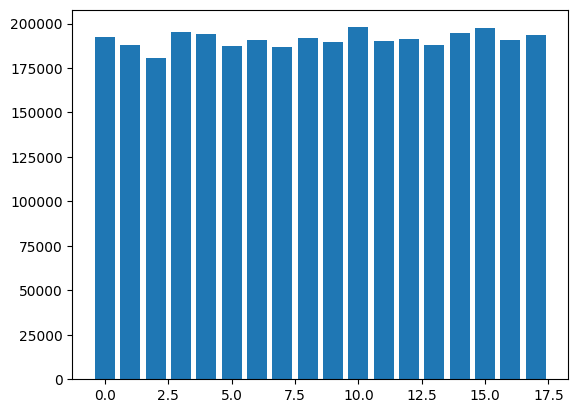

In [7]:
## the distribution of output classes
plt.bar(data["atividade"].value_counts().index, data["atividade"].value_counts().values)
plt.show()

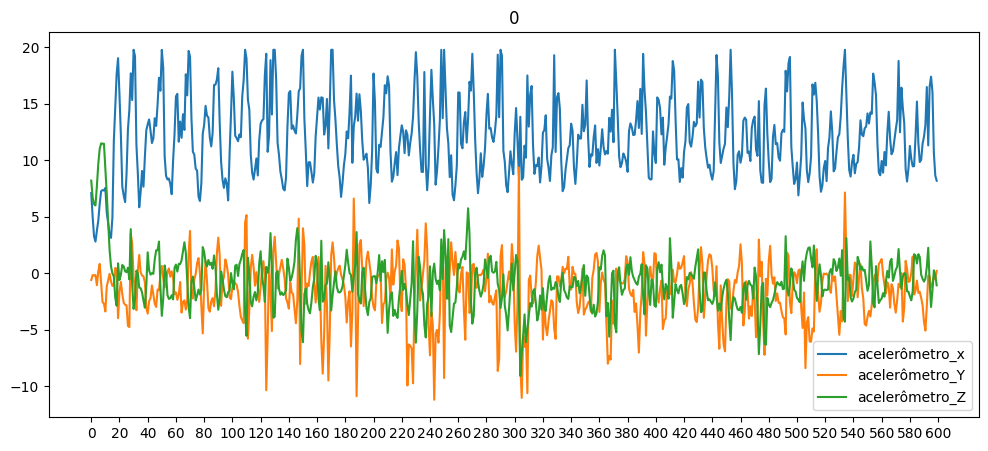

In [8]:
## x,y,z vaues for activity 'sit' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['acelerômetro_x','acelerômetro_Y','acelerômetro_Z']][:600].plot(title='0',subplots=False, figsize=(12, 5))
plt.xticks(range(0, 620, 20))

# Adjust legend position to right below
plt.legend(loc='lower right')
plt.show()

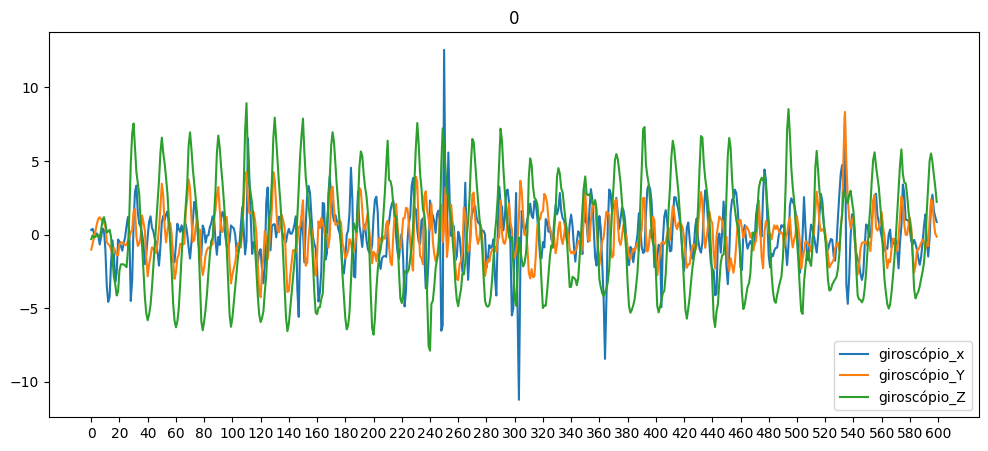

In [9]:
## x,y,z vaues for activity 'stand' 
data[(data['atividade'] == 0 )&(data['pessoa_x']==1600)][['giroscópio_x','giroscópio_Y','giroscópio_Z']][:600].plot(title='0',subplots=False, figsize=(12, 5))
plt.xticks(range(0, 620, 20))
plt.legend(loc='lower right')

plt.show()

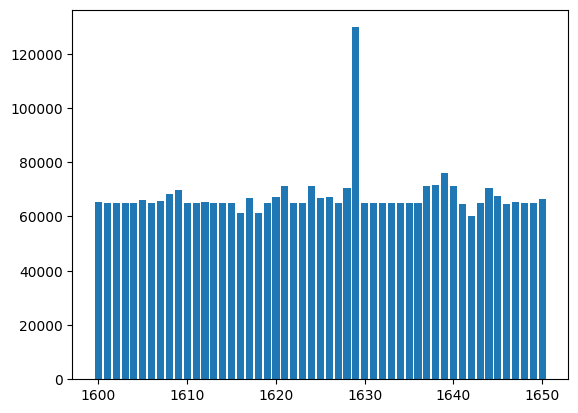

In [10]:
plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [11]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()
print(grouped_data)

atividade      0       1       2       3       4       5       6       7   \
pessoa_x                                                                    
1600       3603.0  3604.0  3604.0  3604.0  3604.0  3604.0  3603.0  3603.0   
1601       3601.0  3602.0  3601.0  3601.0  3602.0  3601.0  3602.0  3602.0   
1602       3603.0  3603.0  3603.0  3603.0  3699.0  3603.0  3603.0  3603.0   
1603       3603.0  3602.0  3602.0  3603.0  3601.0  3601.0  3602.0  3602.0   
1604       3603.0  3603.0  3604.0  3603.0  3603.0  3617.0  3603.0  3603.0   
1605       3603.0  3603.0  3602.0  3602.0  3602.0  3602.0  3615.0  3602.0   
1606       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1607       3603.0  3602.0  3602.0  3601.0  3602.0  3602.0  3601.0  3602.0   
1608       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3609.0   
1609       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1610       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   

In [12]:
data = data[data.pessoa_x!=1629]

In [13]:
grouped_data = data.groupby(['pessoa_x'])['atividade'].value_counts().unstack()
print(grouped_data)

atividade      0       1       2       3       4       5       6       7   \
pessoa_x                                                                    
1600       3603.0  3604.0  3604.0  3604.0  3604.0  3604.0  3603.0  3603.0   
1601       3601.0  3602.0  3601.0  3601.0  3602.0  3601.0  3602.0  3602.0   
1602       3603.0  3603.0  3603.0  3603.0  3699.0  3603.0  3603.0  3603.0   
1603       3603.0  3602.0  3602.0  3603.0  3601.0  3601.0  3602.0  3602.0   
1604       3603.0  3603.0  3604.0  3603.0  3603.0  3617.0  3603.0  3603.0   
1605       3603.0  3603.0  3602.0  3602.0  3602.0  3602.0  3615.0  3602.0   
1606       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1607       3603.0  3602.0  3602.0  3601.0  3602.0  3602.0  3601.0  3602.0   
1608       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3609.0   
1609       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   
1610       3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0  3603.0   

In [14]:
data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609, 1610,
       1611, 1612, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620, 1621,
       1622, 1623, 1624, 1625, 1626, 1627, 1628, 1630, 1631, 1632, 1633,
       1634, 1635, 1636, 1637, 1638, 1639, 1640, 1641, 1642, 1643, 1644,
       1645, 1646, 1647, 1648, 1649, 1650], dtype=int64)

In [15]:
data = data.reset_index(drop=True)

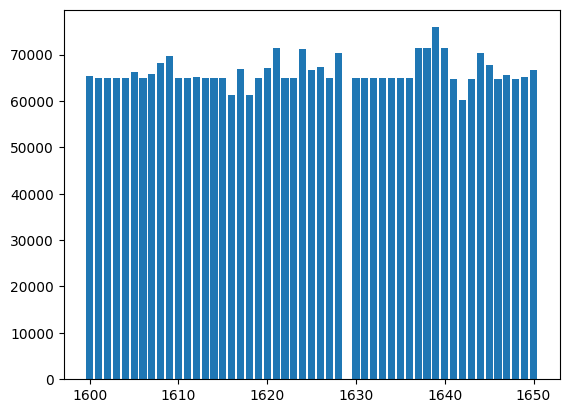

In [16]:
## number of events per user

plt.bar(data["pessoa_x"].value_counts().index, data["pessoa_x"].value_counts().values)
plt.show()

In [17]:
#selecting only activities 0 to 3
data = data[data["atividade"].isin([0,1,2,3,13,16])]

In [18]:
# Define the mapping dictionary
mapping_dict = {13:4,16:5}

In [19]:
data["atividade"] = data["atividade"].replace(to_replace=mapping_dict)

In [20]:
data.shape

(1091039, 10)

In [21]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [22]:
data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [23]:
data.shape

(1091039, 10)

# **Models**

In [24]:
X_test_data = data[data.pessoa_x.isin([1600,1601, 1602, 1603, 1604])]

In [25]:
print(X_test_data.shape)

(108081, 10)


In [26]:
X_test_data = X_test_data.reset_index(drop = True)

In [27]:
X_test_data.head()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
0,1600,0,90426708196641,7.0916250,-0.59166710,8.1955020,90426757696641,0.314944100,-1.02227650,-0.309961600
1,1600,0,90426757696641,4.9727570,-0.15831658,6.6967316,90426807196641,0.387382100,-0.61854124,-0.048971802
2,1600,0,90426807196641,3.2537200,-0.19183542,6.1077580,90426856696641,0.070998540,-0.20947972,-0.195978300
3,1600,0,90426856696641,2.8012160,-0.15592238,5.9976250,90426906196641,0.037975345,0.25497556,-0.156563500
4,1600,0,90426906196641,3.7708676,-1.05135380,7.7310270,90426955696641,0.073129070,0.71943086,-0.001034904


In [28]:
X_test_data.tail()

,pessoa_x,atividade,tempo_acelerômetro,acelerômetro_x,acelerômetro_Y,acelerômetro_Z,tempo_gyro,giroscópio_x,giroscópio_Y,giroscópio_Z
108076,1604,5,693765074530213,-2.2964883,5.0683756,8.192659,693765124458473,0.258029400,-0.059641227,0.195806520
108077,1604,5,693765124458473,-2.0139725,6.6940384,9.212589,693765174386733,0.023671241,0.137432700,0.119107485
108078,1604,5,693765174386733,-1.8846856,6.8329020,10.711359,693765224314993,0.205831450,0.664738600,-0.163187600
108079,1604,5,693765224314993,-1.5303438,6.4546180,9.758467,693765274243253,0.968560800,1.264482500,-0.037486390
108080,1604,5,693765274243253,-2.1073463,2.9830258,9.411307,693765324171513,0.868425900,1.975013900,-0.269714030


In [29]:
X_test_data.pessoa_x.unique()

array([1600, 1601, 1602, 1603, 1604], dtype=int64)

In [30]:
print(f"percentage of validation is {X_test_data.shape[0]/data.shape[0]}")

percentage of validation is 0.09906245331285132


In [31]:
X_test_data['atividade'].value_counts()

atividade
1    18014
2    18014
3    18014
0    18013
4    18013
5    18013
Name: count, dtype: int64

In [32]:
X_test_data = X_test_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z','atividade']]

In [33]:
""" segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data.loc[:, X_test_data.columns != 'pessoa_x'])
print(targets_test.shape)
print(segments_test.shape) """

" segments_test,targets_test = apply_segmentation_no_sliding_window(X_test_data.loc[:, X_test_data.columns != 'pessoa_x'])\nprint(targets_test.shape)\nprint(segments_test.shape) "

In [34]:
segments_test = X_test_data[['pessoa_x','acelerômetro_x', 'acelerômetro_Y', 'acelerômetro_Z', 'giroscópio_x', 'giroscópio_Y', 'giroscópio_Z']]

In [35]:
""" segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)
print(targets_test.shape)
print(segments_test.shape) """

' segments_test,targets_test = delete_segments_not_fully_filled(segments_test,targets_test)\nprint(targets_test.shape)\nprint(segments_test.shape) '

In [36]:
#targets_test = targets_test.reshape(targets_test.shape[0],200)

In [37]:
#print(targets_test.shape)

In [38]:
#print(targets_test)

In [39]:
#labels_test = targets_test[:,0]

In [40]:
#print(labels_test)

In [41]:
#labels_test = targets_test

In [42]:
#print(labels_test)

In [43]:
#print(labels_test.shape)

In [44]:
#labels_test_categorical = to_categorical(labels_test,num_classes=6)

In [45]:
#print(labels_test_categorical)

In [46]:
#print(labels_test_categorical.shape)

In [47]:
#print(labels_test_categorical.shape)

In [48]:
lstm_model = tf.keras.models.load_model(WORKDIR+'/Model/best_models_saved_2024-03-17_21-10-42')

In [49]:
#lstm_model.summary()

In [50]:
#print(segments_test)

In [51]:
#print(labels_test_categorical.shape)

In [52]:
#print(labels_test_categorical)

In [53]:
#loss_test, accuracy_test = lstm_model.evaluate(segments_test, labels_test_categorical)

In [54]:
#redictions_test = lstm_model.predict(segments_test)

In [55]:
#print(predictions_test)

In [56]:
#classes_x_test=np.argmax(predictions_test,axis=1)

In [57]:
#print(classes_x_test)

In [58]:
#labels_test_argmax = np.argmax(labels_test_categorical,axis=1)

In [59]:
#print(labels_test_argmax)

In [60]:
#from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,classification_report
#cm_test = confusion_matrix(labels_test_argmax, classes_x_test)

In [61]:
#disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test)
#disp_test.plot()

In [62]:
#print(classification_report(labels_test_argmax, classes_x_test))

1/1 [==============================] - 0s 295ms/step


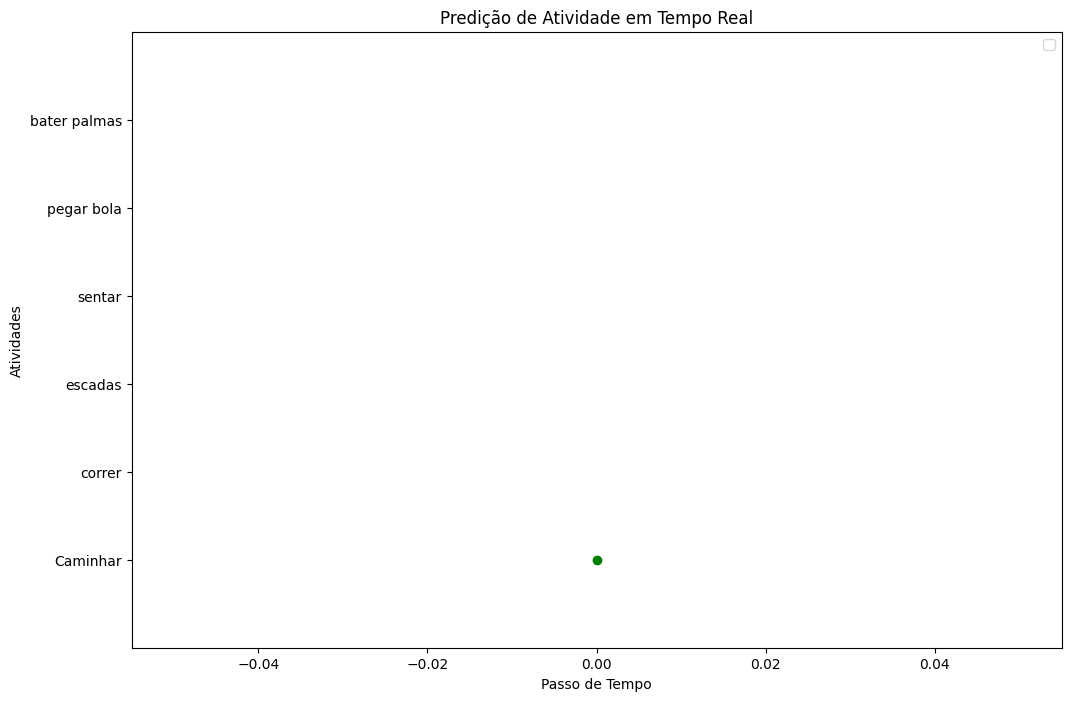

1/1 [==============================] - ETA: 0s

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 22ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 21ms/step


...

1/1 [==============================] - 0s 25ms/step


1/1 [==============================] - ETA: 0s

1/1 [==============================] - ETA: 0s

1/1 [==============================] - 0s 26ms/step


<Figure size 640x480 with 0 Axes>

In [63]:

X_test_data = X_test_data.loc[X_test_data['pessoa_x'] == 1604]
#print(f"quantidade de registros do participante 1604:{X_test_data.shape}")
X_test_data_filtered = X_test_data.loc[:, X_test_data.columns != 'pessoa_x']

first_window_xdata = X_test_data_filtered.iloc[:200,:-1]  # Get the latest window of data    
first_window_label = X_test_data_filtered.iloc[:200,-1]
#mixed_data = False
def prepare_data(test_data,window_size,sensor_data_dim,primeira_janela):
  #global mixed_data  
  global first_window_xdata
  global first_window_label 

  if primeira_janela == True:
    # Assuming data is a continuous stream of sensor readings
    window_xdata = first_window_xdata # Get the latest window of data  
    window_label = first_window_label    
  else:
    #print("%%%%%%%%%%%%%%%%%%%%%%5 NAO EH A PRIMEIRA JANELA")
    window_xdata =pd.concat([first_window_xdata.tail(180),test_data.iloc[:20,:-1] ], ignore_index=True)  
    window_label =pd.concat([first_window_label.tail(180),test_data.iloc[:20,-1]],ignore_index=True)    
    first_window_xdata = window_xdata  
    first_window_label = window_label
     
    

  window_array = window_xdata.values
  window_label_array = window_label.values  
  #print(window_xdata.shape)
  #print(window_label.shape)
  window_label_array = stats.mode(window_label_array).mode[0]
  #print(window_label_array)
  return (window_array.reshape((1, window_size, sensor_data_dim)),window_label_array)  # Reshape for LSTM input

# Real-time prediction loop with plotting
ground_truth = []  # List to store true activity labels
predicted_activities = []  # List to store predicted activity labels
colors = ['green', 'red']  # Green for correct, red for incorrect

count = 0
while not X_test_data_filtered.empty and X_test_data_filtered.shape[0]>199:  
  if count == 0:
    new_xdata, true_activity_label = prepare_data(X_test_data_filtered,200,6,True)
  else:
    new_xdata, true_activity_label = prepare_data(X_test_data_filtered,200,6,False)  
  count = count + 1

  #print(new_xdata)
  #print(new_xdata[1])
  prediction = lstm_model.predict(new_xdata)
  #print(f"imprimindo atividade predita {prediction}")
  predicted_activity = np.argmax(prediction[0])  # Get the class with highest probability
  ground_truth.append(true_activity_label)  # Store true label
  predicted_activities.append(predicted_activity)
  colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predicted_activities, ground_truth)]

  # Prepare data for scatter plot (assuming multiple data points per time step)
  x_data = range(len(predicted_activities))  # Time steps
  y_data = predicted_activities  # Predicted activities (can be modified for other dimensions)
  

  if 1 <= count <= 1:
    # Create the scatter plot with optional error bars (consider for uncertainty visualization)
    plt.figure(figsize=(12, 8))  # Adjust figure size as needed
    plt.scatter(x_data, y_data, marker='o', c = colors)  # Default green for prediction
    # plt.errorbar(x_data, y_data, yerr=error_bars, fmt='o', capsize=5, color=colors[0])  # Uncomment for error bars

    # Update plot with true label if available (consider different color/marker)
    #if true_activity_label is not None:
      #plt.scatter(count, true_activity_label, marker='s', color=colors[1], label='True Label')  # Red for true label (optional)

    plt.xlabel("Passo de Tempo")
    plt.ylabel("Atividades")  # Adjust label based on data
    plt.ylim(-1, 6)  # Adjust y-axis based on number of activity classes (or data range)
    plt.yticks([0, 1, 2, 3, 4, 5], ['Caminhar', 'correr', 'escadas', 'sentar', 'pegar bola', 'bater palmas'])
    plt.title("Predição de Atividade em Tempo Real")
    plt.legend() if true_activity_label is not None else None  # Show legend if true label is displayed
    plt.pause(0.1)  # Adjust pause time for smoother visualization

    plt.ion()
    plt.show()

    # Clear plot for next iteration or consider animation for smoother transition
    plt.clf() 
  #if mixed_data == False:  
    #X_test_data_filtered = X_test_data_filtered.iloc[20:]
  #else:
  X_test_data_filtered = X_test_data_filtered.iloc[20:]
  #print(X_test_data_filtered)   
  #print(f"contando {count}")



In [64]:

print(len(ground_truth))
print(len(predicted_activities))

1071
1071


In [65]:
print(ground_truth)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [66]:
print(len(ground_truth))

1071


In [67]:
print(len(predicted_activities))

1071


In [68]:
print(predicted_activities)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

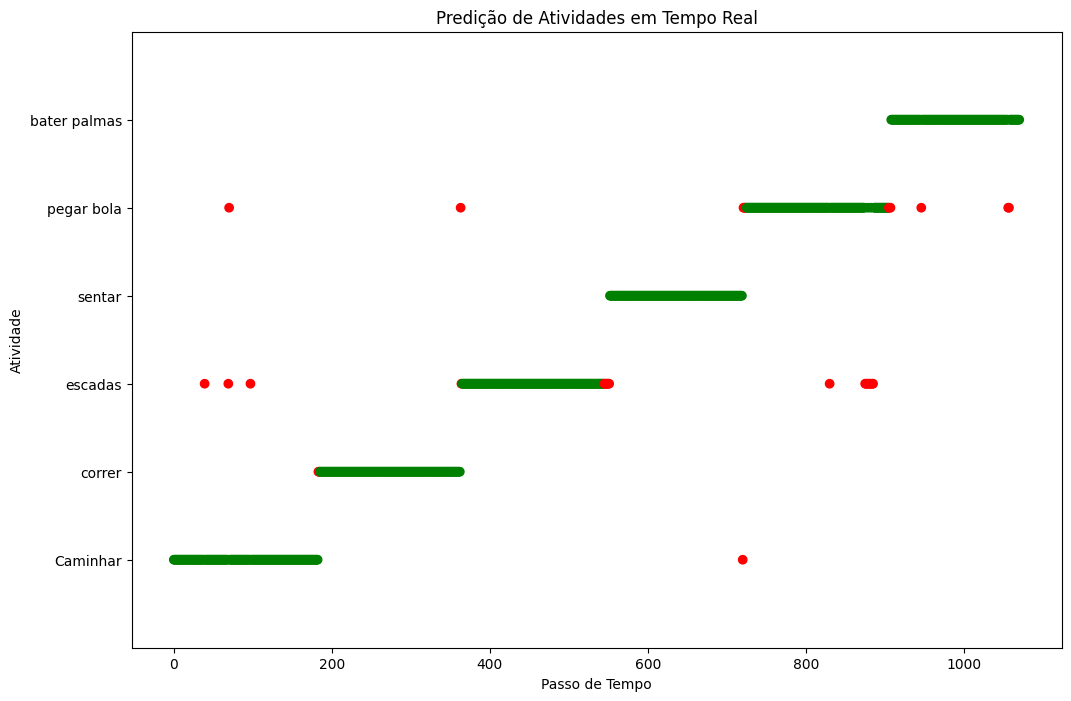

<Figure size 640x480 with 0 Axes>

In [69]:
   
colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predicted_activities, ground_truth)]

# Prepare data for scatter plot (assuming multiple data points per time step)
x_data = range(len(predicted_activities))  # Time steps
y_data = predicted_activities  # Predicted activities (can be modified for other dimensions)


# Create the scatter plot with optional error bars (consider for uncertainty visualization)
plt.figure(figsize=(12, 8))  # Adjust figure size as needed
plt.scatter(x_data, y_data, marker='o', c = colors)  # Default green for prediction
# plt.errorbar(x_data, y_data, yerr=error_bars, fmt='o', capsize=5, color=colors[0])  # Uncomment for error bars

# Update plot with true label if available (consider different color/marker)
#if true_activity_label is not None:
#plt.scatter(count, true_activity_label, marker='s', color=colors[1], label='True Label')  # Red for true label (optional)

plt.xlabel("Passo de Tempo")
plt.ylabel("Atividade")  # Adjust label based on data
plt.ylim(-1, 6)  # Adjust y-axis based on number of activity classes (or data range)
plt.title("Predição de Atividades em Tempo Real")
plt.yticks([0, 1, 2, 3, 4, 5], ['Caminhar', 'correr', 'escadas', 'sentar', 'pegar bola', 'bater palmas'])

#plt.legend() if true_activity_label is not None else None  # Show legend if true label is displayed
plt.pause(0.1)  # Adjust pause time for smoother visualization

plt.ion()
plt.show()

# Clear plot for next iteration or consider animation for smoother transition
plt.clf()

In [70]:

print(len(ground_truth))
print(len(predicted_activities))

1071
1071


In [71]:
print(ground_truth)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [72]:
print(predicted_activities)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 

In [73]:
from sklearn.metrics import accuracy_score
# Calculate accuracy
accuracy = accuracy_score(np.array(ground_truth)
, np.array(predicted_activities))

# Print the accuracy
print("Accuracy:", accuracy)

Accuracy: 0.9663865546218487


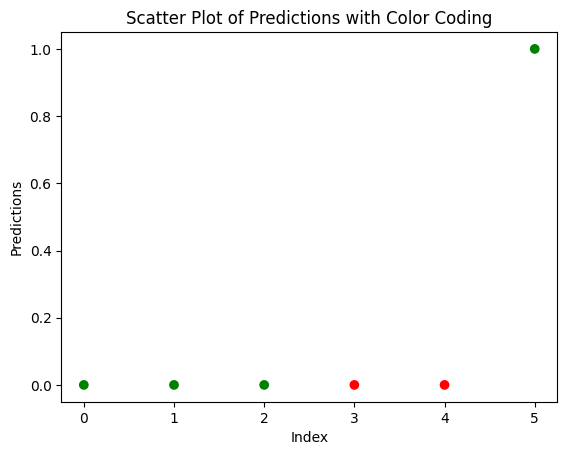

In [74]:
import numpy as np
import matplotlib.pyplot as plt

predictions = np.array([0, 0, 0, 0, 0, 1])
true_values = np.array([0, 0, 0, 1, 1, 1])

colors = ['red' if pred != true_val else 'green' for pred, true_val in zip(predictions, true_values)]

plt.scatter(range(len(predictions)), predictions, c=colors)
plt.xlabel('Index')
plt.ylabel('Predictions')
plt.title('Scatter Plot of Predictions with Color Coding')
plt.show()

In [75]:
## Python Code Example to Include New Data at the End of a DataFrame

# Import pandas library
import pandas as pd

# Create a sample DataFrame
data = {'A': [1, 2, 3],
        'B': ['apple', 'banana', 'cherry']}
df = pd.DataFrame(data)

# Create new data to include
new_data = {'A': [4],
            'B': ['date']}

# Convert new data to DataFrame
new_df = pd.DataFrame(new_data)

# Concatenate the original DataFrame with the new data
df = pd.concat([df, new_df], ignore_index=True)

# Display the updated DataFrame
print(df)

   A       B
0  1   apple
1  2  banana
2  3  cherry
3  4    date


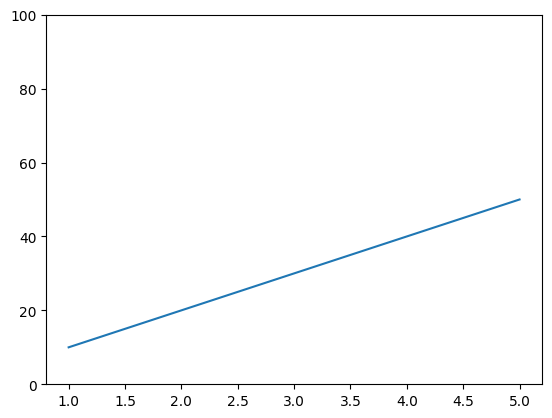

In [76]:


import matplotlib.pyplot as plt

# Sample data
x = [1, 2, 3, 4, 5]
y = [10, 20, 30, 40, 50]

plt.plot(x, y)

# Customize y-axis tick labels
plt.yticks([0, 20, 40, 60, 80, 100], ['0', '20', '40', '60', '80', '100'])

plt.show()